# Notebook 4 — Linear Programming for Graph-Informed Book Selection

**Project:** Goodbooks-10k graph and machine-learning research.

## Objective
Formulate book selection as a binary optimization problem: select a fixed number of books while balancing a transparent relevance proxy with coverage across graph communities.

**Scope limitation:** This is a graph-informed selection experiment, not a fully personalized recommendation system. The relevance score uses book-level metadata, not individual user preferences. For defensible graph-based conclusions, use actual community assignments saved from Notebook 2. The notebook warns if no assignment file is found and creates fallback labels only so the optimization demo can run.

## 1. Imports and project paths

In [18]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Your notebook is inside the "notebooks" folder
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data exists:", DATA_DIR.exists())
print("Books file exists:", (DATA_DIR / "books_clean.csv").exists())
print("Tag summary exists:", (DATA_DIR / "per_book_tag_summary.csv").exists())
print("Tables folder:", TABLE_DIR)

Project root: c:\Users\Nethmi\Desktop\goodbooks-graph-research
Processed data exists: True
Books file exists: True
Tag summary exists: True
Tables folder: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables


## 2. Load processed books and tag summary

In [19]:
books_path = DATA_DIR / "books_clean.csv"
tag_path = DATA_DIR / "per_book_tag_summary.csv"
if not books_path.exists():
    raise FileNotFoundError(f"Missing {books_path}; check PROJECT_ROOT.")
if not tag_path.exists():
    raise FileNotFoundError(f"Missing {tag_path}; check PROJECT_ROOT.")

books = pd.read_csv(books_path)
tag_summary = pd.read_csv(tag_path)
print("Books:", books.shape, books.columns.tolist())
print("Tag summary:", tag_summary.shape, tag_summary.columns.tolist())
display(books.head(3))
display(tag_summary.head(3))

Books: (10000, 23) ['id', 'book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']
Tag summary: (10000, 6) ['id', 'goodreads_book_id', 'title', 'unique_tag_count', 'tag_application_count', 'example_tags']


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...


,id,goodreads_book_id,title,unique_tag_count,tag_application_count,example_tags
0,9984,764165,The Snow Leopard,100,2846,"to-read, travel, non-fiction, favorites, natur..."
1,9983,8539798,"Blue exorcist, Tome 2",100,3838,"to-read, manga, mangá, fantasy, favorites, cur..."
2,9982,12444298,"Feverborn (Fever, #8)",100,11303,"to-read, urban-fantasy, fantasy, paranormal, f..."


## 3. Find saved community assignment files

In [20]:
csv_files = sorted(TABLE_DIR.glob("*.csv"))
for p in csv_files:
    print(p.name)

community_candidates = [
    p for p in csv_files
    if any(term in p.name.lower() for term in
           ["community", "partition", "louvain", "cluster", "membership"])
]
print("\nLikely community files:")
for p in community_candidates:
    print(" -", p.name)

02_alternative_sample_book_ids.csv
02_alternative_sample_results.csv
02_alternative_sample_results_corrected.csv
02_candidate_edges.csv
02_community_assignments.csv
02_community_assignments_with_titles.csv
02_community_metrics.csv
02_filter_sensitivity_results.csv
02_graph_comparison_summary.csv
02_seed_stability_results.csv
03_additional_model_results.csv
03_final_five_model_comparison.csv
03_hist_gradient_boosting_results.csv
03_linear_svm_results.csv
03_model_comparison.csv
03_random_forest_metrics.csv
03_rating_prediction_metrics.csv
04_diversity_weight_sensitivity.csv
04_lp_selected_books.csv
04_lp_vs_baseline_comparison.csv
04_top_k_baseline_books.csv

Likely community files:
 - 02_community_assignments.csv
 - 02_community_assignments_with_titles.csv
 - 02_community_metrics.csv


## 4. Load community assignments

If Notebook 2 saved a community assignment CSV, set `COMMUNITY_FILE` to that file and set the column names below if automatic detection fails. The assignment file must have one book identifier and one community label per row.

**Do not report fallback communities as Louvain communities.**

In [21]:
# Load community assignments
community_path = TABLE_DIR / "02_community_assignments.csv"
all_communities = pd.read_csv(community_path)

print("Available graph types:")
print(all_communities["graph"].value_counts())

# Use Jaccard-weighted graph assignments
community_df = all_communities[
    all_communities["graph"] == "jaccard"
].copy()

community_df = community_df[
    ["goodreads_book_id", "community_id"]
].drop_duplicates()

community_df = community_df.rename(columns={
    "goodreads_book_id": "community_book_id",
    "community_id": "community"
})

community_source = "02_community_assignments.csv — jaccard"

print("\nSelected graph:", community_source)
print("Assignment rows:", len(community_df))
print("Unique assigned books:", community_df["community_book_id"].nunique())
print("Communities:", community_df["community"].nunique())

display(community_df.head())

Available graph types:
graph
unweighted          2000
shared_tag_count    2000
jaccard             2000
Name: count, dtype: int64

Selected graph: 02_community_assignments.csv — jaccard
Assignment rows: 2000
Unique assigned books: 2000
Communities: 8


,community_book_id,community
4000,2049,0
4001,32769,0
4002,2054,0
4003,88077,0
4004,7184,0


## 5. Prepare book-level data and merge tag information

In [22]:
# The prior notebooks used books_clean.id as the internal 1..10000 ID.
if "id" in books.columns:
    books["book_key"] = pd.to_numeric(books["id"], errors="coerce")
elif "book_id" in books.columns:
    books["book_key"] = pd.to_numeric(books["book_id"], errors="coerce")
else:
    raise ValueError("books_clean.csv needs an 'id' or 'book_id' column.")

merged = books.copy()

# Merge tag summary only when a matching key can be identified.
if "goodreads_book_id" in tag_summary.columns and "book_id" in books.columns:
    merged["tag_merge_key"] = pd.to_numeric(merged["book_id"], errors="coerce")
    ts = tag_summary.copy()
    ts["goodreads_book_id"] = pd.to_numeric(ts["goodreads_book_id"], errors="coerce")
    merged = merged.merge(ts, left_on="tag_merge_key", right_on="goodreads_book_id",
                          how="left", suffixes=("", "_tag"))
elif "book_key" in tag_summary.columns:
    merged = merged.merge(tag_summary, on="book_key", how="left", suffixes=("", "_tag"))
else:
    print("No recognized tag-summary join key; proceeding with book metadata.")

print("Prepared table:", merged.shape)
print("Columns:", merged.columns.tolist())
display(merged.head(3))

Prepared table: (10000, 31)
Columns: ['id', 'book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url', 'book_key', 'tag_merge_key', 'id_tag', 'goodreads_book_id', 'title_tag', 'unique_tag_count', 'tag_application_count', 'example_tags']


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,image_url,small_image_url,book_key,tag_merge_key,id_tag,goodreads_book_id,title_tag,unique_tag_count,tag_application_count,example_tags
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...,1,2767052,1,2767052,"The Hunger Games (The Hunger Games, #1)",100,287490,"favorites, currently-reading, young-adult, fic..."
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...,2,3,2,3,Harry Potter and the Sorcerer's Stone (Harry P...,99,780309,"to-read, favorites, fantasy, currently-reading..."
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...,3,41865,3,41865,"Twilight (Twilight, #1)",100,121636,"young-adult, fantasy, favorites, vampires, ya,..."


## 6. Attach community labels

In [23]:
# Remove previous community columns to avoid duplicate merge errors
merged = merged.drop(
    columns=["community", "community_book_id"],
    errors="ignore"
)

# Ensure Goodreads IDs have numeric types
merged["book_id"] = pd.to_numeric(
    merged["book_id"], errors="coerce"
)

community_df["community_book_id"] = pd.to_numeric(
    community_df["community_book_id"], errors="coerce"
)

# Merge Goodreads book IDs with Jaccard community assignments
merged = merged.merge(
    community_df,
    left_on="book_id",
    right_on="community_book_id",
    how="left",
    validate="many_to_one"
)

matched = merged["community"].notna()

print("Total books in metadata:", len(merged))
print("Books matched to Jaccard communities:", int(matched.sum()))
print("Unique matched Goodreads IDs:",
      merged.loc[matched, "book_id"].nunique())
print("Community assignments available:", len(community_df))
print("Distinct matched communities:",
      merged.loc[matched, "community"].nunique())

print(
    f"Coverage of full dataset: {matched.mean():.1%}"
)

print(
    "Coverage of graph-assigned books: "
    f"{merged.loc[matched, 'book_id'].nunique() / community_df['community_book_id'].nunique():.1%}"
)

# Check for unexpected duplicate assignments
assert community_df["community_book_id"].is_unique, (
    "Duplicate Goodreads IDs found in community assignments."
)

assert merged.loc[matched, "book_id"].nunique() == len(community_df), (
    "Not all community-assigned books matched the metadata. Investigate the IDs."
)

display(
    merged.loc[matched, [
        "id", "book_id", "title", "community"
    ]].head(10)
)

Total books in metadata: 10000
Books matched to Jaccard communities: 2000
Unique matched Goodreads IDs: 2000
Community assignments available: 2000
Distinct matched communities: 8
Coverage of full dataset: 20.0%
Coverage of graph-assigned books: 100.0%


,id,book_id,title,community
28,29,18135,Romeo and Juliet,0.0
59,60,1618,The Curious Incident of the Dog in the Night-Time,0.0
78,79,1381,The Odyssey,0.0
91,92,1202,Freakonomics: A Rogue Economist Explores the H...,5.0
101,102,19543,Where the Wild Things Are,2.0
124,125,1420,Hamlet,0.0
126,127,2612,The Tipping Point: How Little Things Can Make ...,6.0
153,154,8852,Macbeth,0.0
156,157,23772,Green Eggs and Ham,2.0
190,191,472331,Watchmen,1.0


## 7. Build a transparent relevance proxy

In [24]:
from sklearn.preprocessing import MinMaxScaler

score_parts, score_notes = [], []
if "average_rating" in merged.columns:
    x = pd.to_numeric(merged["average_rating"], errors="coerce")
    x = x.fillna(x.median())
    score_parts.append(pd.Series(MinMaxScaler().fit_transform(x.to_frame()).ravel(), index=merged.index))
    score_notes.append("average_rating scaled to [0,1]")

count_col = next((c for c in ["work_ratings_count", "ratings_count", "ratings_count_book"]
                  if c in merged.columns), None)
if count_col:
    x = pd.to_numeric(merged[count_col], errors="coerce").fillna(0).clip(lower=0)
    x = np.log1p(x)
    score_parts.append(pd.Series(MinMaxScaler().fit_transform(x.to_frame()).ravel(), index=merged.index))
    score_notes.append(f"log1p({count_col}) scaled to [0,1]")

if not score_parts:
    raise ValueError("No recognized average_rating or ratings-count column for relevance score.")

merged["relevance_score"] = sum(score_parts) / len(score_parts)
print("Score components:", score_notes)
display(merged["relevance_score"].describe())

Score components: ['average_rating scaled to [0,1]', 'log1p(work_ratings_count) scaled to [0,1]']


count    10000.000000
mean         0.450661
std          0.089316
min          0.119315
25%          0.392333
50%          0.443999
75%          0.500787
max          0.917000
Name: relevance_score, dtype: float64

## 8. Define candidate set and LP parameters

In [25]:
K = 20
MAX_PER_COMMUNITY = 5
DIVERSITY_WEIGHT = 0.15

candidates = merged.dropna(subset=["book_key", "community", "relevance_score"]).copy()
candidates["book_key"] = pd.to_numeric(candidates["book_key"], errors="coerce")
candidates = candidates.dropna(subset=["book_key"]).drop_duplicates("book_key")
candidates["community"] = candidates["community"].astype(str)
candidates["relevance_score"] = pd.to_numeric(candidates["relevance_score"], errors="coerce")
candidates = candidates.dropna(subset=["relevance_score"])

if len(candidates) < K:
    raise ValueError(f"Only {len(candidates)} candidates; need at least K={K}.")
print("Eligible books:", len(candidates))
print("Communities:", candidates["community"].nunique())
display(candidates["community"].value_counts().head(10).rename("candidate_books").to_frame())

Eligible books: 2000
Communities: 8


,candidate_books
community,
0.0,415
5.0,410
7.0,292
6.0,240
2.0,181
1.0,170
4.0,160
3.0,132


## 9. Solve the binary Linear Programming model

Let \(x_i=1\) when book \(i\) is selected, and \(z_c=1\) when at least one selected book belongs to community \(c\).

Maximize \(\sum_i r_i x_i + \lambda\sum_c z_c\), subject to selecting exactly \(K\) books, limiting each community to at most \(M\) selected books, and linking \(z_c\) to the selected books in community \(c\). All variables are binary.

SciPy's `milp` solver handles this mixed-integer linear formulation.

In [26]:
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix

def solve_selection(diversity_weight, candidate_frame, k, max_per_community, time_limit=120):
    frame = candidate_frame.reset_index(drop=True)
    comms = sorted(frame["community"].astype(str).unique())
    n, m = len(frame), len(comms)
    c = np.zeros(n + m)
    c[:n] = -frame["relevance_score"].to_numpy()  # milp minimizes
    c[n:] = -float(diversity_weight)

    A = lil_matrix((1 + 2*m, n + m), dtype=float)
    lb = np.full(1 + 2*m, -np.inf)
    ub = np.full(1 + 2*m, np.inf)

    A[0, :n] = 1
    lb[0] = k
    ub[0] = k

    community_array = frame["community"].astype(str).to_numpy()
    row = 1
    for j, community in enumerate(comms):
        idx = np.flatnonzero(community_array == community)
        A[row, idx] = 1
        ub[row] = max_per_community
        row += 1
        # z_j <= sum(x_i in community)
        A[row, n+j] = 1
        A[row, idx] = -1
        ub[row] = 0
        row += 1

    result = milp(
        c=c,
        integrality=np.ones(n + m, dtype=int),
        bounds=Bounds(np.zeros(n + m), np.ones(n + m)),
        constraints=LinearConstraint(A.tocsr(), lb, ub),
        options={"time_limit": time_limit}
    )
    if not result.success or result.x is None:
        raise RuntimeError(f"Optimization failed: {result.message}")
    chosen = frame.loc[result.x[:n] > 0.5].copy()
    return chosen, result

selected, solver_result = solve_selection(DIVERSITY_WEIGHT, candidates, K, MAX_PER_COMMUNITY)
selected = selected.sort_values("relevance_score", ascending=False).reset_index(drop=True)
print("Solver:", solver_result.message)
print("Selected books:", len(selected))
print("Communities covered:", selected["community"].nunique())
display_cols = [c for c in ["title", "authors", "average_rating", "relevance_score", "community"] if c in selected.columns]
display(selected[display_cols])

Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Selected books: 20
Communities covered: 8


,title,authors,average_rating,relevance_score,community
0,Where the Wild Things Are,Maurice Sendak,4.22,0.721557,2.0
1,Watchmen,"Alan Moore, Dave Gibbons, John Higgins",4.35,0.716801,1.0
2,Green Eggs and Ham,"Dr. Seuss, לאה נאור",4.29,0.712785,2.0
3,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.72,0.709162,7.0
4,Romeo and Juliet,"William Shakespeare, Robert Jackson",3.73,0.688418,0.0
5,How the Grinch Stole Christmas!,Dr. Seuss,4.36,0.684450,2.0
6,Redeeming Love,Francine Rivers,4.48,0.677033,6.0
7,The Color Purple,Alice Walker,4.17,0.676985,5.0
8,The Lorax,Dr. Seuss,4.35,0.674525,2.0
9,Holy Bible: King James Version,Anonymous,4.43,0.669887,6.0


## 10. Compare against the top-K relevance baseline

In [27]:
baseline = candidates.sort_values("relevance_score", ascending=False).head(K).copy()

def summarize_selection(frame, method):
    return {
        "method": method,
        "selected_books": len(frame),
        "distinct_communities": frame["community"].nunique(),
        "mean_relevance": frame["relevance_score"].mean(),
        "minimum_relevance": frame["relevance_score"].min(),
        "maximum_books_from_one_community": int(frame["community"].value_counts().max())
    }

comparison = pd.DataFrame([
    summarize_selection(baseline, "Top-K relevance baseline"),
    summarize_selection(selected, "LP relevance + diversity")
])
display(comparison)

comparison.to_csv(TABLE_DIR / "04_lp_vs_baseline_comparison.csv", index=False)
selected.to_csv(TABLE_DIR / "04_lp_selected_books.csv", index=False)
baseline.to_csv(TABLE_DIR / "04_top_k_baseline_books.csv", index=False)
print("Saved comparison and selected-book tables to", TABLE_DIR)

,method,selected_books,distinct_communities,mean_relevance,minimum_relevance,maximum_books_from_one_community
0,Top-K relevance baseline,20,6,0.674375,0.648462,5
1,LP relevance + diversity,20,8,0.671623,0.616076,5


Saved comparison and selected-book tables to c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables


## 11. Visualize selection comparison

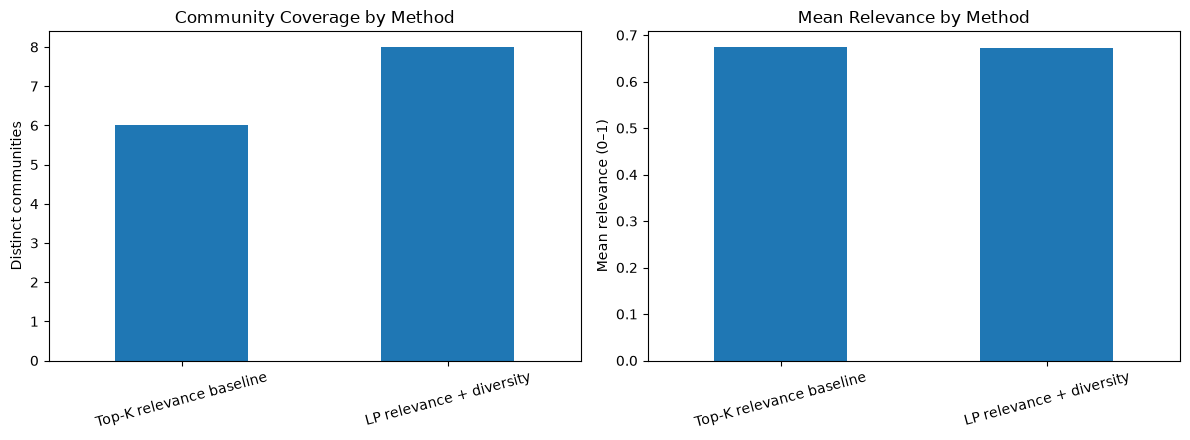

Saved figure: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\figures\04_lp_vs_baseline.png


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparison.set_index("method")["distinct_communities"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Community Coverage by Method")
axes[0].set_ylabel("Distinct communities")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)

comparison.set_index("method")["mean_relevance"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean Relevance by Method")
axes[1].set_ylabel("Mean relevance (0–1)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "04_lp_vs_baseline.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved figure:", FIGURE_DIR / "04_lp_vs_baseline.png")

## 12. Sensitivity analysis: diversity weight

In [29]:
sensitivity_rows = []
for weight in [0.00, 0.05, 0.15, 0.30, 0.50]:
    try:
        chosen, res = solve_selection(weight, candidates, K, MAX_PER_COMMUNITY)
        sensitivity_rows.append({
            "diversity_weight": weight,
            "selected_books": len(chosen),
            "distinct_communities": chosen["community"].nunique(),
            "mean_relevance": chosen["relevance_score"].mean(),
            "max_books_from_one_community": int(chosen["community"].value_counts().max()),
            "solver_status": res.message
        })
    except Exception as exc:
        sensitivity_rows.append({
            "diversity_weight": weight, "selected_books": np.nan,
            "distinct_communities": np.nan, "mean_relevance": np.nan,
            "max_books_from_one_community": np.nan, "solver_status": str(exc)
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)
sensitivity_df.to_csv(TABLE_DIR / "04_diversity_weight_sensitivity.csv", index=False)
print("Saved:", TABLE_DIR / "04_diversity_weight_sensitivity.csv")

,diversity_weight,selected_books,distinct_communities,mean_relevance,max_books_from_one_community,solver_status
0,0.00,20,6,0.674375,5,Optimization terminated successfully. (HiGHS S...
1,0.05,20,8,0.671623,5,Optimization terminated successfully. (HiGHS S...
2,0.15,20,8,0.671623,5,Optimization terminated successfully. (HiGHS S...
3,0.30,20,8,0.671623,5,Optimization terminated successfully. (HiGHS S...
4,0.50,20,8,0.671623,5,Optimization terminated successfully. (HiGHS S...


Saved: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\04_diversity_weight_sensitivity.csv


In [30]:
# Recalculate the comparison from the current corrected selections
comparison = pd.DataFrame([
    summarize_selection(baseline, "Top-K relevance baseline"),
    summarize_selection(selected, "LP relevance + diversity")
])

display(comparison)

comparison.to_csv(
    TABLE_DIR / "04_lp_vs_baseline_comparison.csv",
    index=False
)

print("Updated comparison saved.")

,method,selected_books,distinct_communities,mean_relevance,minimum_relevance,maximum_books_from_one_community
0,Top-K relevance baseline,20,6,0.674375,0.648462,5
1,LP relevance + diversity,20,8,0.671623,0.616076,5


Updated comparison saved.


In [31]:
print("Current selected communities:",
      selected["community"].nunique())

print("Current mean relevance:",
      round(selected["relevance_score"].mean(), 4))

print("Current baseline communities:",
      baseline["community"].nunique())

print("Current baseline mean relevance:",
      round(baseline["relevance_score"].mean(), 4))

Current selected communities: 8
Current mean relevance: 0.6716
Current baseline communities: 6
Current baseline mean relevance: 0.6744


## 13. Save configuration

In [32]:
config = {
    "notebook": "04_Linear_Programming_Book_Recommendation",
    "objective": "maximize relevance proxy plus diversity bonus for distinct communities",
    "K": K,
    "max_per_community": MAX_PER_COMMUNITY,
    "diversity_weight": DIVERSITY_WEIGHT,
    "community_source": community_source,
    "candidate_books": int(len(candidates)),
    "candidate_communities": int(candidates["community"].nunique()),
    "selected_books": int(len(selected)),
    "selected_communities": int(selected["community"].nunique()),
    "relevance_components": score_notes,
    "interpretation_warning": (
    "Uses actual Jaccard-weighted Louvain communities "
    "from Notebook 2."
)

}
with open(TABLE_DIR / "04_lp_experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)
print(json.dumps(config, indent=2))

{
  "notebook": "04_Linear_Programming_Book_Recommendation",
  "objective": "maximize relevance proxy plus diversity bonus for distinct communities",
  "K": 20,
  "max_per_community": 5,
  "diversity_weight": 0.15,
  "community_source": "02_community_assignments.csv \u2014 jaccard",
  "candidate_books": 2000,
  "candidate_communities": 8,
  "selected_books": 20,
  "selected_communities": 8,
  "relevance_components": [
    "average_rating scaled to [0,1]",
    "log1p(work_ratings_count) scaled to [0,1]"
  ],
  "interpretation_warning": "Uses actual Jaccard-weighted Louvain communities from Notebook 2."
}


In [33]:
# Inspect the original community assignment file
community_path = TABLE_DIR / "02_community_assignments.csv"

community_check = pd.read_csv(community_path)

print("Community assignment shape:", community_check.shape)
print("Community assignment columns:")
print(community_check.columns.tolist())

display(community_check.head(10))

print("\nBook identifiers in books_clean.csv:")
print(books[["id", "book_id"]].head())

print("\nCommunity assignment identifier ranges:")
for col in community_check.columns:
    if "id" in col.lower() or "book" in col.lower():
        print(f"\n{col}")
        print(community_check[col].head().tolist())

Community assignment shape: (6000, 3)
Community assignment columns:
['graph', 'goodreads_book_id', 'community_id']


,graph,goodreads_book_id,community_id
0,unweighted,32769,0
1,unweighted,96259,0
2,unweighted,2054,0
3,unweighted,88077,0
4,unweighted,7184,0
5,unweighted,7186,0
6,unweighted,18452,0
7,unweighted,400412,0
8,unweighted,3103,0
9,unweighted,11299,0



Book identifiers in books_clean.csv:
   id  book_id
0   1  2767052
1   2        3
2   3    41865
3   4     2657
4   5     4671

Community assignment identifier ranges:

goodreads_book_id
[32769, 96259, 2054, 88077, 7184]

community_id
[0, 0, 0, 0, 0]


### Results and Discussion: Linear Programming

The binary optimization model selected 20 books from the candidate set using a metadata-based relevance score and community-diversity constraints. The selected books were assigned to communities identified in the Jaccard-weighted book network.

Compared with the top-K relevance baseline, the LP-based selection increased community coverage from six to eight communities. Both methods selected 20 books and respected the maximum of five books per community. The baseline achieved a mean relevance score of 0.674375, while the optimized selection achieved 0.671623.

These results illustrate a trade-off between the relevance proxy and community coverage. The LP model achieved complete coverage of the eight available communities with an approximately 0.41% reduction in mean relevance relative to the baseline. The sensitivity analysis also showed that a diversity weight of 0.05 was sufficient to obtain coverage of all eight communities in this experiment; increasing the weight further did not change the reported selection.

The findings suggest that binary optimization can incorporate graph community structure into book selection while retaining a high average metadata-based relevance score. However, the relevance measure is based on book ratings and popularity rather than individual user preferences. Consequently, the experiment demonstrates constrained, graph-informed selection rather than validated personalized recommendation performance.